<div style="background-color: #FFFF00; color: #000000; padding: 12px 18px; font-family: Arial, Helvetica, sans-serif;">
<strong style="color: #000000;">MINE-4101 Ciencia de Datos Aplicada · Universidad de los Andes · 2026-20</strong><br>
<span style="color: #000000;">Proyecto final · Entrega final · Actividad 9</span>
</div>

# Estrategia de validación y selección del modelo

Cómo se entrenan, comparan y eligen los modelos, y la partición de los datos en entrenamiento, validación y prueba.

**Integrantes**

- Daniel Felipe Triviño Santana
- Nicolas Bedoya Figueroa
- Joubert Daniel Álvarez
- Gabriel Bejarano

**Qué pide el enunciado** (actividad 9, 5 % de la entrega final): definir la estrategia de experimentación para entrenar y seleccionar el mejor modelo, separar los datos en entrenamiento, validación y prueba, y un reporte breve que verifique que los subconjuntos conservan la distribución del conjunto original.

**Punto de partida:** el enfoque analítico de la primera entrega (sección 4 del [reporte](../reporte/reporte.pdf)) propuso una partición estratificada, porque solo hay una transición entre vigencias (de 2025 a 2026) y no alcanza para una validación temporal. Lee los datos del [notebook 08](08-preparacion-de-datos.ipynb).

**Cómo hacerlo:** el [sitio de prácticas del curso](https://datascience-uniandes.github.io/PracticasMachineLearning/) es la referencia principal; para esta actividad, las guías [división de los datos](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/division-datos/), [validación cruzada](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/validacion-cruzada/), [selección de hiperparámetros](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/seleccion-hiperparametros/), [GridSearchCV](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/gridsearchcv/) y [chi-cuadrado](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/chi-cuadrado/). Si el notebook se aparta de ellas, lo dice y explica por qué.

**Estado:** las seis etapas tienen código e interpretación. Pendiente de revisión del equipo.

## Tabla de contenido

| | Etapa | Qué se hace |
| --- | --- | --- |
| 1 | [Librerías y configuración](#librerias) | Librerías, rutas y estilo |
| 2 | [Carga de los datos preparados](#carga) | Leer la salida del notebook 08 |
| 3 | [Estrategia de experimentación](#estrategia) | Cómo se eligen los hiperparámetros y el mejor modelo |
| 4 | [Partición](#particion) | Entrenamiento, validación y prueba, estratificada |
| 5 | [Verificación de las distribuciones](#distribucion) | Comparar cada subconjunto con el conjunto completo |
| 6 | [Guardar la partición](#guardar) | El archivo que lee el notebook 10 |

<a id="librerias"></a>

## 1. Librerías y configuración

Las librerías están en el entorno del proyecto (ver el [README](../../README.md#entorno-de-python)). Las rutas de los archivos que pasan de un notebook a otro, la semilla y las columnas reservadas están en [utilidades_modelado.py](utilidades_modelado.py), junto a este notebook.

In [1]:
import platform

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

# Rutas, semilla, columnas reservadas y estilo (utilidades_modelado.py, en esta carpeta)
import utilidades_modelado as um

um.configurar()

In [2]:
# Versiones con las que se ejecutó el notebook
print(f"Python {platform.python_version()}")
for libreria in (np, pd, mpl, sns, sklearn):
    print(f"{libreria.__name__} {libreria.__version__}")

Python 3.12.15
numpy 2.3.5
pandas 2.3.3
matplotlib 3.10.0
seaborn 0.13.2
sklearn 1.9.1


<a id="carga"></a>

## 2. Carga de los datos preparados

**Salidas.** El repositorio es público: ninguna salida puede mostrar datos personales ni nada que identifique al municipio, y los valores de `um.COLUMNAS_RESERVADAS` no se muestran (ver la etapa 2 del [notebook 06](../../entrega-1/notebooks/06-entendimiento-de-los-datos.ipynb)). La variable objetivo y las que salen de la facturación se muestran solo agregadas.

In [3]:
um.exigir(um.ARCHIVO_PREPARADO, "ejecute antes el notebook 08-preparacion-de-datos.ipynb")
preparados = pd.read_parquet(um.ARCHIVO_PREPARADO)
preparados.shape

(19149, 27)

<a id="estrategia"></a>

## 3. Estrategia de experimentación

- **Partición única 70/15/15** en entrenamiento, validación y prueba ([división de los datos](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/division-datos/)). Solo hay una transición entre vigencias (de 2025 a 2026), así que no hay cómo validar en el tiempo; la partición es aleatoria entre predios.
- **Estratificada por el pago de 2026 y el historial de 2025 a la vez** (seis estratos). Así cada subconjunto conserva la tasa de pago de cada grupo, y las métricas por grupo del notebook 10 se calculan sobre la misma composición. El estrato más pequeño, los 9 predios que no pagaron 2025 y sí 2026, queda repartido en los tres subconjuntos.
- **Selección de hiperparámetros en validación.** Cada algoritmo se entrena con varios conjuntos de hiperparámetros sobre entrenamiento y se compara en validación ([selección de hiperparámetros](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/seleccion-hiperparametros/)). Con 13 400 predios en entrenamiento y 2 870 en validación, un solo conjunto de validación da estimaciones estables; la validación cruzada queda como alternativa si dos candidatos empatan.
- **Criterio de elección: log-loss en validación.** El producto usa las probabilidades para el recaudo esperado, así que importa que estén bien calibradas. El ROC-AUC y la curva de calibración, en total y por grupo, acompañan la decisión. Todos se comparan con la línea base: repetir el pago de 2025.
- **Precisión, recall y F1 de la clase "no paga".** La Alcaldía actuaría sobre los predios que probablemente no pagarán (por ejemplo, para priorizar el cobro), así que esa es la clase de interés: la precisión dice qué parte de los señalados de verdad no pagó, el recall qué parte de los que no pagaron quedó señalada y el F1 resume las dos ([precisión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/precision/), [recall](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/recall/), [F1](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/f1/)). Dependen del umbral de probabilidad: se reportan con el umbral de 0,5 y con el que maximiza el F1 en validación, junto con la [matriz de confusión](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/matriz-confusion/), en total y por grupo. Complementan al log-loss, que sigue siendo el criterio de elección porque el recaudo esperado usa la probabilidad y no la clase.
- **Prueba se usa una sola vez,** al final, para el modelo elegido.

<a id="particion"></a>

## 4. Partición

Dos llamadas a `train_test_split`, con `random_state=um.SEMILLA` y el estrato combinado en `stratify`: la primera separa el 15 % para prueba y la segunda toma, del 85 % restante, la parte que equivale al 15 % del total para validación.

In [4]:
estrato = preparados[um.GRUPO] + " · " + preparados[um.OBJETIVO].map({1: "pagó 2026", 0: "no pagó 2026"})

resto, prueba = train_test_split(preparados.index, test_size=0.15, stratify=estrato, random_state=um.SEMILLA)
entrenamiento, validacion = train_test_split(resto, test_size=0.15 / 0.85, stratify=estrato.loc[resto],
                                             random_state=um.SEMILLA)

ORDEN = ["entrenamiento", "validación", "prueba"]
subconjunto = pd.Series("", index=preparados.index)
subconjunto.loc[entrenamiento], subconjunto.loc[validacion], subconjunto.loc[prueba] = ORDEN
assert subconjunto.ne("").all()

# Predios por estrato y subconjunto (cifras agregadas)
tabla = pd.crosstab(estrato.rename("estrato"), subconjunto.rename("subconjunto"))[ORDEN]
tabla.loc["Total"] = tabla.sum()
tabla["% del total"] = (tabla[ORDEN].sum(axis=1) / len(preparados) * 100).round(1)
tabla

subconjunto,entrenamiento,validación,prueba,% del total
estrato,,,,
No pagó 2025 · no pagó 2026,1886,404,404,14.10
No pagó 2025 · pagó 2026,7,1,1,0.00
Pagó 2025 · no pagó 2026,1729,371,371,12.90
Pagó 2025 · pagó 2026,7032,1508,1508,52.50
Sin registro 2025 · no pagó 2026,1206,258,258,9.00
Sin registro 2025 · pagó 2026,1543,331,331,11.50
Total,13403,2873,2873,100.00


**Interpretación.** Quedan 13 403 predios en entrenamiento y 2 873 en validación y en prueba (70 %, 15 % y 15 %). Cada estrato se repartió en la misma proporción. Los 9 predios que no pagaron 2025 y sí 2026 quedaron 7 en entrenamiento y 1 en cada uno de los otros dos subconjuntos: en ese grupo, validación y prueba tienen un solo pago, así que el notebook 10 no le calcula ROC-AUC ni calibración propios (ver el desbalance en el notebook 06).

<a id="distribucion"></a>

## 5. Verificación de las distribuciones

Cada subconjunto debe parecerse al conjunto completo. Para las categóricas, la proporción de cada categoría por subconjunto y una prueba chi-cuadrado de independencia entre la categoría y el subconjunto ([chi-cuadrado](https://datascience-uniandes.github.io/PracticasMachineLearning/ayudas/chi-cuadrado/)), con la V de Cramér como tamaño del efecto. Para las numéricas, una prueba de Kolmogórov-Smirnov de dos muestras entre validación y entrenamiento, y entre prueba y entrenamiento. En los dos casos, $H_0$: la distribución es la misma en los subconjuntos. Lo esperado es no rechazarla.

In [5]:
def chi2_subconjunto(col):
    # Las categorías con menos de 40 predios se agrupan en "Otra", para que las frecuencias
    # esperadas no queden por debajo de 5 (guía de chi-cuadrado)
    valores = preparados[col].astype(str)
    frecuencia = valores.map(valores.value_counts())
    t = pd.crosstab(valores.where(frecuencia >= 40, "Otra"), subconjunto)
    chi2, p, gl, esperadas = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1)))
    return {"chi2": chi2, "gl": gl, "p": p, "V de Cramér": v, "celdas esperadas < 5": int((esperadas < 5).sum())}


CATEGORICAS_REVISADAS = [um.OBJETIVO, um.GRUPO, "novedad_numero_predial", "condicion_predio",
                         "destinacion_economica", "zona", "resultado_visita"]
pruebas_cat = pd.DataFrame({c: chi2_subconjunto(c) for c in CATEGORICAS_REVISADAS}).T
display(pruebas_cat.astype(float).round({"chi2": 2, "p": 3, "V de Cramér": 3}))

# Proporciones por subconjunto de la variable objetivo, el historial y la condición del predio
for col in [um.OBJETIVO, um.GRUPO, "condicion_predio"]:
    prop = pd.crosstab(preparados[col], subconjunto.rename("subconjunto"), normalize="columns")[ORDEN].mul(100)
    prop.insert(0, "completo", preparados[col].value_counts(normalize=True).mul(100))
    print(f"=== {col} (% de predios)")
    display(prop.round(1))

,chi2,gl,p,V de Cramér,celdas esperadas < 5
pago_2026,0.00,2.00,1.00,0.00,0.00
historial_2025,0.00,4.00,1.00,0.00,0.00
novedad_numero_predial,3.90,8.00,0.87,0.01,2.00
condicion_predio,13.99,6.00,0.03,0.02,0.00
destinacion_economica,18.36,18.00,0.43,0.02,0.00
zona,3.81,2.00,0.15,0.01,0.00
resultado_visita,13.30,10.00,0.21,0.02,0.00


=== pago_2026 (% de predios)


subconjunto,completo,entrenamiento,validación,prueba
pago_2026,,,,
0,36.00,36.00,36.00,36.00
1,64.00,64.00,64.00,64.00


=== historial_2025 (% de predios)


subconjunto,completo,entrenamiento,validación,prueba
historial_2025,,,,
No pagó 2025,14.10,14.10,14.10,14.10
Pagó 2025,65.40,65.40,65.40,65.40
Sin registro 2025,20.50,20.50,20.50,20.50


=== condicion_predio (% de predios)


subconjunto,completo,entrenamiento,validación,prueba
condicion_predio,,,,
Condominio.Unidad_Predial,12.00,12.10,11.80,11.70
Informal,2.30,2.30,1.80,3.20
NPH,28.20,28.10,28.20,28.80
PH.Unidad_Predial,57.40,57.50,58.10,56.30


In [6]:
NUMERICAS_REVISADAS = ["log_avaluo", "log_area_construida", "log_area_terreno", "pisos_edificio",
                       "anio_construccion", "n_unidades"]
filas = {}
for col in NUMERICAS_REVISADAS:
    ent = preparados.loc[subconjunto == "entrenamiento", col].dropna()
    fila = {"mediana entrenamiento": ent.median()}
    for nombre in ["validación", "prueba"]:
        otro = preparados.loc[subconjunto == nombre, col].dropna()
        ks = stats.ks_2samp(otro, ent)
        fila[f"mediana {nombre}"] = otro.median()
        fila[f"KS {nombre}"] = ks.statistic
        fila[f"p {nombre}"] = ks.pvalue
    filas[col] = fila
pd.DataFrame(filas).T.round(3)

,mediana entrenamiento,mediana validación,KS validación,p validación,mediana prueba,KS prueba,p prueba
log_avaluo,8.37,8.36,0.01,0.64,8.35,0.01,0.94
log_area_construida,2.06,2.04,0.01,0.84,2.05,0.02,0.54
log_area_terreno,2.29,2.29,0.01,0.88,2.31,0.02,0.28
pisos_edificio,2.00,2.00,0.01,0.95,2.00,0.02,0.34
anio_construccion,2018.00,2018.00,0.01,0.97,2019.00,0.03,0.11
n_unidades,2.00,2.00,0.02,0.57,1.00,0.02,0.34


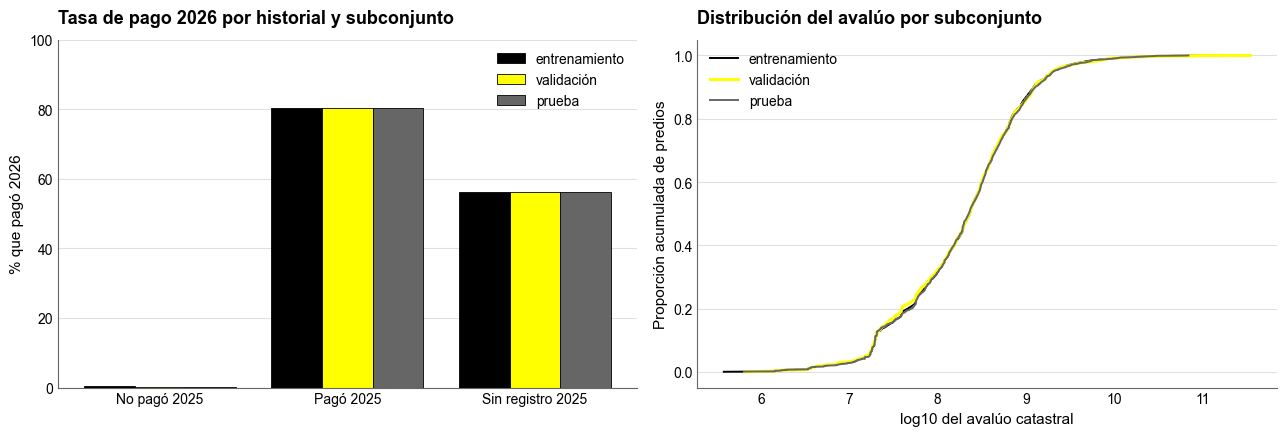

In [7]:
# Izquierda: tasa de pago 2026 por historial en cada subconjunto. Derecha: distribución acumulada del
# log-avalúo en cada subconjunto
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
tasa = preparados.groupby([um.GRUPO, subconjunto])[um.OBJETIVO].mean().unstack()[ORDEN] * 100
colores = {"entrenamiento": um.NEGRO, "validación": um.AMARILLO, "prueba": um.GRIS}
x = np.arange(len(tasa))
for k, nombre in enumerate(ORDEN):
    ax1.bar(x + (k - 1) * 0.27, tasa[nombre], width=0.27, color=colores[nombre], edgecolor=um.NEGRO,
            linewidth=0.6, label=nombre)
ax1.set_xticks(x, tasa.index)
ax1.set_ylabel("% que pagó 2026"); ax1.set_ylim(0, 100)
ax1.set_title("Tasa de pago 2026 por historial y subconjunto"); ax1.legend()

for nombre in ORDEN:
    valores = np.sort(preparados.loc[subconjunto == nombre, "log_avaluo"].dropna())
    ax2.plot(valores, np.arange(1, len(valores) + 1) / len(valores), color=colores[nombre],
             linewidth=2.2 if nombre == "validación" else 1.4, label=nombre)
ax2.set_xlabel("log10 del avalúo catastral"); ax2.set_ylabel("Proporción acumulada de predios")
ax2.set_title("Distribución del avalúo por subconjunto"); ax2.legend()
plt.tight_layout(); plt.show()

**Interpretación.** Los tres subconjuntos conservan la distribución del conjunto completo.

- **Estratificadas.** La variable objetivo y el historial tienen exactamente las mismas proporciones en los tres (chi-cuadrado = 0, p = 1): 64,0 % pagó 2026, y la tasa de pago de cada historial es igual en entrenamiento, validación y prueba (gráfica izquierda).
- **Otras categóricas.** Las categorías con menos de 40 predios se agrupan en "Otra" para que la prueba sea confiable; solo la novedad conserva dos celdas con frecuencia esperada menor que 5, por los 14 englobes. Ninguna se asocia con el subconjunto en una medida apreciable (V de Cramér de 0,02 o menos). La condición del predio da p < 0,05, por los informales (2,3 % del total; 1,8 % en validación y 3,2 % en prueba), pero con V = 0,02 la diferencia es despreciable. Son 450 predios, muy pocos para estratificar también por ellos.
- **Numéricas.** Kolmogórov-Smirnov no rechaza $H_0$ en ninguna (p ≥ 0,11), con estadísticos de 0,03 o menos y medianas casi iguales. Las curvas acumuladas del avalúo se superponen (gráfica derecha).

Con esto, las diferencias de desempeño entre entrenamiento, validación y prueba que aparezcan en el notebook 10 se podrán atribuir al modelo y no a la partición.

<a id="guardar"></a>

## 6. Guardar la partición

Un archivo con `id_predio` y el subconjunto de cada predio, para que el notebook 10 use exactamente la misma partición. Al final, la evidencia de la matriz que recibe el modelo: el preprocesador del notebook 08 (`um.crear_preprocesador`) ajustado solo con entrenamiento y aplicado a validación y prueba.

In [8]:
particion = pd.DataFrame({"id_predio": preparados["id_predio"], "subconjunto": subconjunto})
assert particion["id_predio"].is_unique and len(particion) == len(preparados)
particion.to_parquet(um.ARCHIVO_PARTICION, index=False)
print(f"Guardado en {um.ARCHIVO_PARTICION.relative_to(um.RAIZ)}")
particion["subconjunto"].value_counts()[ORDEN].to_frame("predios")

Guardado en datos\modelado\particion.parquet


,predios
subconjunto,
entrenamiento,13403
validación,2873
prueba,2873


In [9]:
# El preprocesador se ajusta solo con entrenamiento y se aplica a los otros dos subconjuntos
preprocesador = um.crear_preprocesador().fit(preparados.loc[subconjunto == "entrenamiento", um.CARACTERISTICAS])
nombres = pd.Series(preprocesador.get_feature_names_out())
matrices = {nombre: preprocesador.transform(preparados.loc[subconjunto == nombre, um.CARACTERISTICAS])
            for nombre in ORDEN}
display(pd.DataFrame({nombre: {"filas": m.shape[0], "columnas": m.shape[1], "faltantes": int(np.isnan(m).sum())}
                      for nombre, m in matrices.items()}).T)
print("Columnas por tipo de transformación:", nombres.str.split("__").str[0].value_counts().to_dict())

# Las numéricas estandarizadas: media 0 y desviación 1 en entrenamiento, y cerca de eso en los otros dos
numericas = nombres.str.startswith("numericas__").to_numpy()
pd.DataFrame({nombre: {"media": m[:, numericas].mean(), "desviación media": m[:, numericas].std(axis=0).mean()}
              for nombre, m in matrices.items()}).T.round(3)

,filas,columnas,faltantes
entrenamiento,13403,58,0
validación,2873,58,0
prueba,2873,58,0


Columnas por tipo de transformación: {'categoricas': 39, 'numericas': 14, 'binarias': 5}


,media,desviación media
entrenamiento,0.00,1.00
validación,-0.01,1.02
prueba,0.01,1.10


**Interpretación.** Ajustado solo con entrenamiento, el preprocesador produce 58 columnas: 39 del one-hot, 14 de las numéricas (10 variables y 4 indicadores de faltante) y las 5 binarias. Validación y prueba se transforman sin errores ni faltantes, aunque tengan categorías que entrenamiento no vio. Las numéricas quedan con media 0 y desviación 1 en entrenamiento, y cerca de eso en validación y prueba (desviación media de 1,02 y 1,10), como se espera cuando la media y la desviación salen solo de entrenamiento.